# TP 2 · Taxi : baseline médiane vs Ridge

Courses de taxi NYC, janvier 2025 (20 000 courses). On veut prédire la **durée d'une course** (`duration_min`) → c'est une **régression** (on prédit un nombre, pas une classe).

**Objectif :**
1. Charger le CSV et reprendre les fenêtres temporelles du cours
2. Comparer une baseline médiane et une régression Ridge
3. Tracer les résidus selon la prédiction ou l'heure
4. Expliquer un gain éventuel et une limite persistante

## 0. Setup

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline

df2 = pd.read_csv("data/taxi_2025_01_cours.csv")

## 1. Regarder les données

- `PULocationID` : zone de départ (un numéro de quartier)
- `pickup` : date/heure de départ
- `duration_min` : durée de la course (la cible)
- `hour`, `weekday` : heure (0–23) et jour de la semaine (0 = lundi)

In [2]:
df2.columns

Index(['PULocationID', 'pickup', 'duration_min', 'hour', 'weekday'], dtype='str')

In [3]:
df2.head(20)

,PULocationID,pickup,duration_min,hour,weekday
0,75,2025-01-01 00:03:01,14.183333,0,2
1,41,2025-01-01 00:05:19,5.766667,0,2
2,256,2025-01-01 00:11:53,7.483333,0,2
3,166,2025-01-01 00:19:59,5.883333,0,2
4,82,2025-01-01 00:22:24,4.233333,0,2
5,168,2025-01-01 00:22:29,3.500000,0,2
6,255,2025-01-01 00:24:37,25.866667,0,2
7,236,2025-01-01 00:24:44,9.216667,0,2
8,66,2025-01-01 00:25:05,36.083333,0,2
9,41,2025-01-01 00:25:23,10.300000,0,2


In [4]:
df2.dtypes

PULocationID      int64
pickup              str
duration_min    float64
hour              int64
weekday           int64
dtype: object

## 2. Split temporel

Ici on ne mélange **pas** au hasard : on coupe par **date**, comme dans la vraie vie (on entraîne sur le passé, on prédit le futur).

| Split | Période |
|---|---|
| train | 1er → 19 janvier |
| val | 20 → 25 janvier |
| test | 26 → 31 janvier |

Un split aléatoire mélangerait des courses du même jour dans train et test → le modèle « connaîtrait » déjà les conditions de ces journées (météo, trafic…) et paraîtrait meilleur qu'il ne l'est.

`pickup` est du texte au format `AAAA-MM-JJ HH:MM:SS`, donc la comparaison `<` entre chaînes marche dans l'ordre chronologique.

In [5]:
train = df2[df2["pickup"] < "2025-01-20"]

In [6]:
val = df2[(df2["pickup"] < "2025-01-26") & (df2["pickup"] >= "2025-01-20")] 

In [7]:
test = df2[(df2["pickup"] < "2025-02-01") & (df2["pickup"] >= "2025-01-26")] 

In [8]:
print(len(train), len(val), len(test))
print(len(train) + len(val) + len(test))
print(train["pickup"].min(), train ["pickup"].max())
print(val["pickup"].min(), val ["pickup"].max())
print(test["pickup"].min(), test ["pickup"].max())

11782 4009 4209
20000
2025-01-01 00:03:01 2025-01-19 23:58:37
2025-01-20 00:09:13 2025-01-25 23:58:58
2025-01-26 00:01:46 2025-01-31 23:54:07


## 3. Features et cible

In [9]:
FEATURES2 = ["PULocationID", "hour", "weekday"]
TARGET2 = "duration_min"

In [10]:
X_train2, y_train2 = train[FEATURES2], train[TARGET2]
X_val2, y_val2 = val[FEATURES2], val[TARGET2]

## 4. Baseline : la médiane

`DummyRegressor(strategy="median")` ignore les features et prédit **toujours la même durée** : la médiane de train (≈ 11,5 min). C'est le score minimum à battre : un modèle qui fait pire ne sert à rien.

**MAE** (Mean Absolute Error) = l'erreur moyenne en minutes, en valeur absolue.

In [11]:
base = DummyRegressor(strategy="median")
base.fit(X_train2, y_train2)
pred_base = base.predict(X_val2)
mae_base = mean_absolute_error(y_val2, pred_base)
print(mae_base)

6.263735761203957


## 5. Ridge

Ridge = régression linéaire avec une petite pénalité (`alpha`) qui empêche les coefficients d'exploser.

Les trois features sont des **numéros**, pas des quantités : la zone 200 n'est pas « deux fois » la zone 100, et 23 h n'est pas « plus » que 2 h au sens linéaire. On les passe donc **toutes en one-hot** : le modèle apprend un effet propre à chaque zone, chaque heure et chaque jour.

In [12]:
prep2 = ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), FEATURES2)])

In [13]:
model = make_pipeline(prep2, Ridge(alpha=1.0, solver="lsqr"))
model.fit(X_train2, y_train2)
pred_ridge = model.predict(X_val2)
mae_ridge = mean_absolute_error(y_val2, pred_ridge)
print(mae_ridge)

6.438622380310614


**Lecture :** baseline **6,26 min**, Ridge **6,44 min** → la Ridge est **un peu pire** que la baseline ! Pas de gain ici.

Pourquoi ? La Ridge minimise l'erreur **au carré** : elle se fait tirer vers le haut par les quelques courses très longues. La médiane, elle, est justement la valeur qui minimise l'erreur **absolue** (la MAE). On juge la Ridge avec une métrique qui avantage la baseline.

## 6. Résidus

**Résidu** = vraie valeur − prédiction.
- résidu > 0 → la course a duré **plus** que prévu (sous-estimation)
- résidu < 0 → elle a duré **moins** (sur-estimation)

In [14]:
residuals = y_val2 - pred_ridge

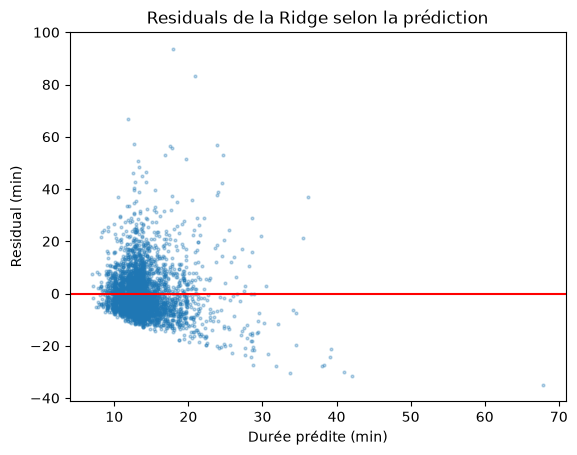

In [15]:
plt.scatter(pred_ridge, residuals, s=4, alpha=0.3)
plt.axhline(0, color="red")
plt.xlabel("Durée prédite (min)")
plt.ylabel("Residual (min)")
plt.title("Residuals de la Ridge selon la prédiction")
plt.show()

**Lecture :** le nuage est **dense en bas** (petits résidus, souvent légèrement négatifs) et **diffus en haut** : quelques courses durent 20, 50, jusqu'à 90 min de plus que prévu. Le résidu médian est ≈ −2 min : pour une course typique, la Ridge prévoit un peu trop long, à cause de ces longues courses qui la tirent vers le haut.

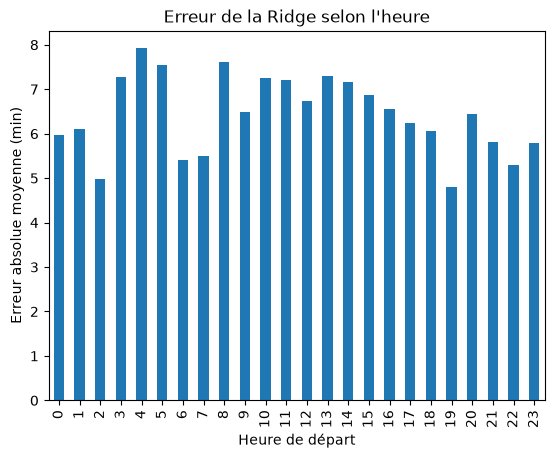

In [16]:
erreur_par_heure = residuals.abs().groupby(X_val2["hour"]).mean()
erreur_par_heure.plot(kind="bar")
plt.xlabel("Heure de départ")
plt.ylabel("Erreur absolue moyenne (min)")
plt.title("Erreur de la Ridge selon l'heure")
plt.show()

**Lecture :** l'erreur varie selon l'heure : environ **7–8 min vers 3–5 h et 8 h**, et **~5 min vers 2 h et 19 h**. Le modèle est moins fiable à certains moments de la journée.

## 7. Conclusion

- **Gain :** aucun gain sur la validation (6,44 vs 6,26). Une piste serait d'entraîner sur la même métrique qu'on mesure (par ex. prédire la médiane par groupe, ou une loss absolue), ou d'ajouter des interactions zone × heure.
- **Limite persistante :** la feature la plus importante **manque** — la **destination / la distance**. Avec seulement « d'où, à quelle heure, quel jour », on ne peut pas savoir si la course fait 2 km ou 20 km. Aucun modèle ne compense une information absente.
- Le **test** (26–31 janvier) n'a pas été utilisé : on le garde pour une évaluation finale.